`ngs` env

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from Bio.Seq import Seq
from Bio import motifs

In [5]:
import logomaker

In [ ]:
# # For now I'm using Lexi's version of the table, but we should probably ask Marco for the latest version
# # https://github.com/ArcInstitute/crispr_cas9_sgrna_design/blob/main/whole_genome_sgrna_libraries/wgCRISPRaV3_table_crispra_sgrnas.xlsx
# CRISPRaV3_table_sub_12 = pd.read_excel('../wgCRISPRaV3_table_crispra_sgrnas.xlsx', sheet_name='1-2 library').set_index('sgID_AB')
# CRISPRaV3_table_sub_34 = pd.read_excel('../wgCRISPRaV3_table_crispra_sgrnas.xlsx', sheet_name='3-4 library').set_index('sgID_AB')
# CRISPRaV3_table_sub_56 = pd.read_excel('../wgCRISPRaV3_table_crispra_sgrnas.xlsx', sheet_name='5-6 library').set_index('sgID_AB')

# CRISPRaV3_table_sub_12.insert(0,'sublibrary','h_dual_1')
# CRISPRaV3_table_sub_34.insert(0,'sublibrary','h_dual_2')
# CRISPRaV3_table_sub_56.insert(0,'sublibrary','h_dual_3')

In [ ]:
# CRISPRaV3_table = pd.concat([
#     CRISPRaV3_table_sub_12,
#     CRISPRaV3_table_sub_34,
#     CRISPRaV3_table_sub_56
# ])

# CRISPRaV3_table['sequence'] = CRISPRaV3_table['protospacer_A'] + ';' + CRISPRaV3_table['protospacer_B']

# CRISPRaV3_table.to_csv(
#     '../CRISPRa_v3_human_librarytable.txt.gz', sep='\t', compression='gzip'
# )

In [108]:
library_CRISPRi_v2 = pd.read_csv(
    '../CRISPRi_v2_human_librarytable.txt.gz',
    sep='\t', 
    header=0, 
    index_col=0,
    low_memory=False
)

library_CRISPRa_v2 = pd.read_csv(
    '../CRISPRa_v2_human_librarytable.txt.gz',
    sep='\t', 
    header=0, 
    index_col=0,
    low_memory=False
)

library_CRISPRi_v3 = pd.read_csv(
    '../CRISPRi_v3_human_librarytable.txt.gz',
    sep='\t', 
    header=0, 
    index_col=0,
    low_memory=False
)

library_CRISPRa_v3 = pd.read_csv(
    '../CRISPRa_v3_human_librarytable.txt.gz',
    sep='\t', 
    header=0, 
    index_col=0,
    low_memory=False
)

In [111]:
# library.sequence.str.len().unique()

# 

___

In [51]:
def draw_logo(library,ax,title,seq_col='sequence'):
    m = motifs.create(library[seq_col].to_list()); l = len(library[seq_col].to_list())
    run_logomaker(m, l, ax); ax.set_title(title)
    ax.xaxis.set_major_locator(ticker.MultipleLocator())
    return ax


def run_logomaker(m,l,ax):
    df = pd.DataFrame(m.counts,dtype=int)

    for n in ['A','T','C','G']: 
        df[n] = df[n] / l

    crp_logo = logomaker.Logo(df,
                             fade_probabilities=True,
                              shade_below=.5,
                              fade_below=.5,
                              ax=ax
                              # font_name='Arial Rounded MT Bold'
                             )

in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...


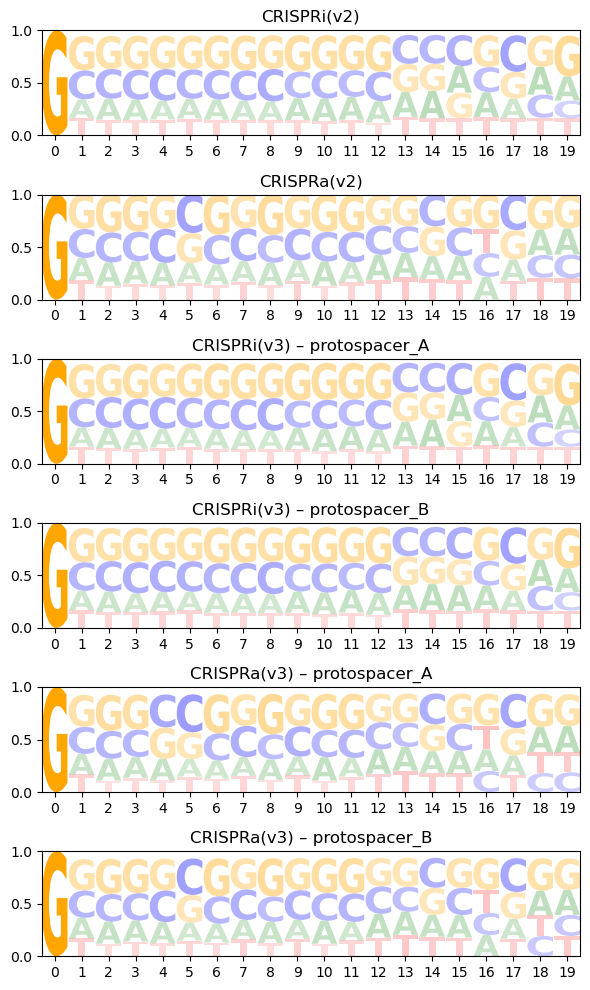

In [122]:
fig, axes = plt.subplots(6, 1,figsize=(6,10), sharey=True, tight_layout=True)

draw_logo(library_CRISPRi_v2,axes[0],'CRISPRi(v2)')

draw_logo(library_CRISPRa_v2,axes[1],'CRISPRa(v2)')

draw_logo(library_CRISPRi_v3,axes[2],'CRISPRi(v3) – protospacer_A',seq_col='protospacer_A')
draw_logo(library_CRISPRi_v3,axes[3],'CRISPRi(v3) – protospacer_B',seq_col='protospacer_B')

draw_logo(library_CRISPRa_v3,axes[4],'CRISPRa(v3) – protospacer_A',seq_col='protospacer_A')
draw_logo(library_CRISPRa_v3,axes[5],'CRISPRa(v3) – protospacer_B',seq_col='protospacer_B')

plt.tight_layout()
plt.savefig('CRISPRai_v2_or_v3_motif_logo.pdf')
plt.show()

#

In [119]:
%load_ext watermark

In [120]:
%watermark

Last updated: 2024-11-09T00:09:19.395863-08:00

Python implementation: CPython
Python version       : 3.11.9
IPython version      : 8.25.0

Compiler    : GCC 12.3.0
OS          : Linux
Release     : 6.8.0-48-generic
Machine     : x86_64
Processor   : x86_64
CPU cores   : 64
Architecture: 64bit



In [ ]:
%watermark --iversions

logomaker : 0.8
Bio       : 1.83
matplotlib: 3.6.3
pandas    : 1.5.3

